# AED 03 — El consolidado: nulos, tipos y calidad

Control de calidad de `../datos/consolidado_capacidad.csv` (4006 filas,
una por celda y check-up): valores nulos, duplicados, tipos, rangos,
valores fuera de rango, monotonía y consistencia entre las dos escalas
de SoH. Es el archivo que alimenta los modelos, así que aquí se verifica
que esté limpio antes de usarlo.

**Dataset:** Luh & Blank (2024), RADAR4KIT v2, *result data*,
DOI [10.35097/1969](https://doi.org/10.35097/1969).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cons = pd.read_csv(Path("../datos/consolidado_capacidad.csv"))
print("forma:", cons.shape)
print("columnas:", list(cons.columns))
print(cons.dtypes.to_string())
print()
print(cons.head(3).to_string())

forma: (4006, 19)
columnas: ['cell_id', 'condicion', 'replica', 'slave', 'slot', 'cu', 'timestamp_s', 'num_cycles_op', 'q_chg_Ah', 'q_dischg_Ah', 'q_Ah', 'soh_cap', 'soh_nominal', 'age_type', 'age_temp', 'age_soc', 'age_chg_rate', 'age_dischg_rate', 'age_profile']
cell_id             object
condicion            int64
replica              int64
slave                int64
slot                 int64
cu                   int64
timestamp_s        float64
num_cycles_op        int64
q_chg_Ah           float64
q_dischg_Ah        float64
q_Ah               float64
soh_cap            float64
soh_nominal        float64
age_type           float64
age_temp           float64
age_soc            float64
age_chg_rate       float64
age_dischg_rate    float64
age_profile        float64

  cell_id  condicion  replica  slave  slot  cu   timestamp_s  num_cycles_op  q_chg_Ah  q_dischg_Ah      q_Ah    soh_cap  soh_nominal  age_type  age_temp  age_soc  age_chg_rate  age_dischg_rate  age_profile
0  P001_1      

/home/hatch/workspace/venvs/baterias/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Valores nulos

¿Dónde hay huecos y por qué?

In [2]:
nulos = cons.isna().sum()
nulos = nulos[nulos > 0]
print("columnas con nulos:")
print((nulos / len(cons) * 100).round(3).astype(str) + " %  (" + nulos.astype(str) + " filas)")
print()
print("columnas sin nulos:", (cons.isna().sum() == 0).sum(), "de", len(cons.columns))
print()
print("las 8 CU con una sola medida (falta carga o descarga):")
una = cons[cons["q_chg_Ah"].isna() | cons["q_dischg_Ah"].isna()]
print(una[["cell_id", "cu", "q_chg_Ah", "q_dischg_Ah", "q_Ah"]].round(3).to_string(index=False))

columnas con nulos:
q_chg_Ah       0.025 %  (1 filas)
q_dischg_Ah    0.175 %  (7 filas)
dtype: object

columnas sin nulos: 17 de 19

las 8 CU con una sola medida (falta carga o descarga):
cell_id  cu  q_chg_Ah  q_dischg_Ah  q_Ah
 P041_3  20     1.478          NaN 1.478
 P068_1  26     1.375          NaN 1.375
 P068_2  25     1.349          NaN 1.349
 P073_1  11     1.280          NaN 1.280
 P073_2  11     1.290          NaN 1.290
 P073_3  12     1.445          NaN 1.445
 P073_3  13       NaN        0.973 0.973
 P074_3  16     1.379          NaN 1.379


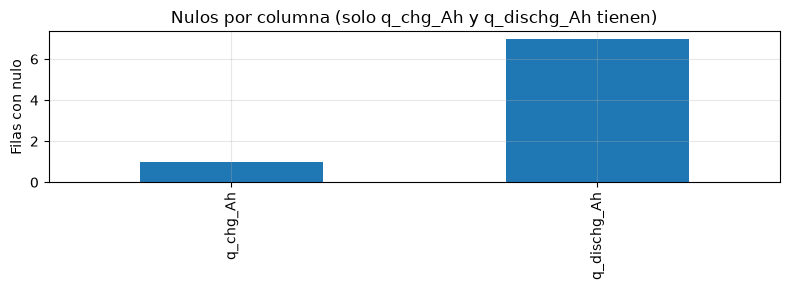

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
nulos.plot(kind="bar", ax=ax)
ax.set_ylabel("Filas con nulo")
ax.set_title("Nulos por columna (solo q_chg_Ah y q_dischg_Ah tienen)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura:** los únicos nulos son las 8 CU con una sola medida (7 sin
descarga, 1 sin carga). `q_Ah` y `soh_cap` no tienen nulos porque son la
media de las medidas disponibles. No hay nada que imputar: el modelo usa
`q_Ah`/`soh_cap` y las dos columnas laterales solo se conservan para
auditar la diferencia carga–descarga.

## 2. Duplicados y secuencia de CU

Cada celda debe tener una fila por CU, con CU consecutivos desde 0.

In [4]:
print("filas duplicadas (cell_id, cu):", cons.duplicated(["cell_id", "cu"]).sum())
huecos = []
for cid, g in cons.groupby("cell_id"):
    cus = sorted(g["cu"].unique())
    if cus != list(range(cus[0], cus[-1] + 1)):
        huecos.append(cid)
print("celdas con huecos en la secuencia de CU:", len(huecos))
print()
print("celdas por condición:", cons.groupby("condicion")["cell_id"].nunique().value_counts().to_dict())
print("condiciones distintas:", cons["condicion"].nunique())
print("condiciones sin datos de edad (NaN en age_*):",
      cons[["age_type", "age_temp", "age_soc", "age_chg_rate", "age_dischg_rate", "age_profile"]].isna().any(axis=1).sum())

filas duplicadas (cell_id, cu): 0
celdas con huecos en la secuencia de CU: 0

celdas por condición: {3: 76}
condiciones distintas: 76
condiciones sin datos de edad (NaN en age_*): 0


## 3. Tipos y rangos

¿Qué tipo tiene cada columna y en qué rango se mueve?

In [5]:
print(cons.describe().T[["min", "max", "mean", "std"]].round(3).to_string())
print()
for col in ["age_type", "age_temp", "age_soc", "age_chg_rate", "age_dischg_rate", "age_profile"]:
    print(col, "->", sorted(cons[col].unique()))

                          min           max          mean           std
condicion        1.000000e+00  7.600000e+01  3.706800e+01  2.479400e+01
replica          1.000000e+00  3.000000e+00  2.000000e+00  8.170000e-01
slave            1.000000e+00  1.900000e+01  1.068800e+01  5.268000e+00
slot             0.000000e+00  1.100000e+01  6.751000e+00  3.258000e+00
cu               0.000000e+00  2.800000e+01  1.138000e+01  8.245000e+00
timestamp_s      1.665624e+09  1.717179e+09  1.685173e+09  1.495135e+07
num_cycles_op    0.000000e+00  6.388400e+04  2.465117e+03  5.948228e+03
q_chg_Ah         1.280000e+00  3.176000e+00  2.578000e+00  2.770000e-01
q_dischg_Ah      9.730000e-01  2.971000e+00  2.557000e+00  2.950000e-01
q_Ah             9.730000e-01  2.972000e+00  2.566000e+00  2.850000e-01
soh_cap         -3.511000e+01  9.811400e+01  7.109000e+01  1.902500e+01
soh_nominal      3.244500e+01  9.905700e+01  8.554500e+01  9.512000e+00
age_type         1.000000e+00  3.000000e+00  1.852000e+00  7.180

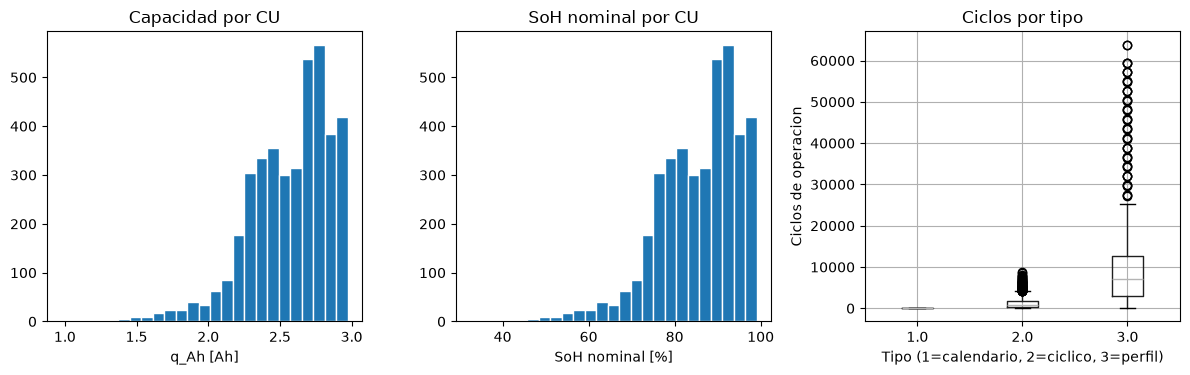

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(cons["q_Ah"], bins=25, edgecolor="white")
axes[0].set_xlabel("q_Ah [Ah]")
axes[0].set_title("Capacidad por CU")
axes[1].hist(cons["soh_nominal"], bins=25, edgecolor="white")
axes[1].set_xlabel("SoH nominal [%]")
axes[1].set_title("SoH nominal por CU")
cons.boxplot(column="num_cycles_op", by="age_type", ax=axes[2])
axes[2].set_xlabel("Tipo (1=calendario, 2=ciclico, 3=perfil)")
axes[2].set_ylabel("Ciclos de operacion")
axes[2].set_title("Ciclos por tipo")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Lectura:** las columnas `age_*` son códigos (tipo, temperatura, SoC,
tasas, perfil) guardados como `float64` por la unión con los cfg. Para
usarlas como variables conviene pasarlas a `int` o a categoría, según el
modelo. `num_cycles_op` vale 0 en calendario y crece mucho en perfil
(hasta 63.884 ciclos): es un contador de ciclos de operación, no una
medida de envejecimiento comparable entre tipos.

## 4. Valores fuera de rango

¿Hay valores imposibles? ¿Qué significa un `soh_cap` negativo?

In [7]:
print("q_Ah > 3,0 Ah:", (cons["q_Ah"] > 3.0).sum())
print("q_chg_Ah > 3,0 Ah:", (cons["q_chg_Ah"] > 3.0).sum(),
      "| max q_chg_Ah:", round(cons["q_chg_Ah"].max(), 3))
print("q_Ah < 1,0 Ah:", (cons["q_Ah"] < 1.0).sum())
print("soh_nominal > 100:", (cons["soh_nominal"] > 100).sum(),
      "| soh_nominal < 0:", (cons["soh_nominal"] < 0).sum())
print("soh_cap > 100:", (cons["soh_cap"] > 100).sum(),
      "| soh_cap < 0:", (cons["soh_cap"] < 0).sum())
print()
neg = cons[cons["soh_cap"] < 0]
print("filas con soh_cap < 0:", len(neg), "| celdas:", neg["cell_id"].nunique())
print(neg[["cell_id", "cu", "q_Ah", "soh_cap", "soh_nominal"]].round(3).to_string(index=False))

q_Ah > 3,0 Ah: 0
q_chg_Ah > 3,0 Ah: 7 | max q_chg_Ah: 3.176
q_Ah < 1,0 Ah: 1
soh_nominal > 100: 0 | soh_nominal < 0: 0
soh_cap > 100: 0 | soh_cap < 0: 16

filas con soh_cap < 0: 16 | celdas: 15
cell_id  cu  q_Ah  soh_cap  soh_nominal
 P033_1  22 1.491   -0.569       49.715
 P041_3  20 1.478   -1.489       49.255
 P042_1  21 1.492   -0.555       49.723
 P046_2  28 1.462   -2.503       48.748
 P059_3   6 1.483   -1.130       49.435
 P068_1  26 1.375   -8.325       45.838
 P068_2  25 1.349  -10.035       44.983
 P068_3  27 1.386   -7.608       46.196
 P070_3   7 1.465   -2.317       48.841
 P073_1  11 1.280  -14.658       42.671
 P073_2  11 1.290  -13.998       43.001
 P073_3  12 1.445   -3.662       48.169
 P073_3  13 0.973  -35.110       32.445
 P074_2  15 1.357   -9.504       45.248
 P074_3  16 1.379   -8.046       45.977
 P076_1  27 1.415   -5.666       47.167


**Lectura:** un `soh_cap` negativo no es un error: es la escala del
dataset con piso en el 50 % nominal. `soh_cap = 0` equivale a Q = 1,5 Ah;
por debajo de 1,5 Ah el valor sale negativo. Son 16 filas de 15 celdas,
las más envejecidas (la peor es P073_3 en CU 13, con Q = 0,973 Ah y
SoH nominal 32,4 %). En escala nominal ningún valor sale de [0, 100].
Las 7 filas con `q_chg_Ah > 3,0` son ruido de estimación en la carga;
la media `q_Ah` nunca supera 2,972 Ah, por eso se usa la media.

## 5. Monotonía y ruido

La capacidad debería bajar (casi siempre) de un CU al siguiente.
¿Cuánto sube y dónde?

In [8]:
c2 = cons.sort_values(["cell_id", "cu"]).copy()
c2["dq_Ah"] = c2.groupby("cell_id")["q_Ah"].diff()
pos = c2[c2["dq_Ah"] > 0]
print("celdas con algun aumento de Q entre CU:", c2[c2["dq_Ah"] > 0]["cell_id"].nunique(), "de 228")
print("pares de CU con aumento:", len(pos), "de", c2["dq_Ah"].notna().sum())
print("aumento positivo: mediana %.4f Ah, max %.4f Ah" % (pos["dq_Ah"].median(), pos["dq_Ah"].max()))
print("aumentos > 0,05 Ah:", (c2["dq_Ah"] > 0.05).sum(), "| > 0,1 Ah:", (c2["dq_Ah"] > 0.1).sum())
print()
print("mayores aumentos:")
print(c2.nlargest(5, "dq_Ah")[["cell_id", "cu", "q_Ah", "dq_Ah"]].round(4).to_string(index=False))
print()
print("celdas con timestamp no creciente:", sum(
    (g["timestamp_s"].diff().dropna() <= 0).any()
    for _, g in cons.sort_values("cu").groupby("cell_id")))
print("celdas con num_cycles_op decreciente:", sum(
    (g["num_cycles_op"].diff().dropna() < 0).any()
    for _, g in cons.sort_values("cu").groupby("cell_id")))

celdas con algun aumento de Q entre CU: 64 de 228
pares de CU con aumento: 88 de 3778
aumento positivo: mediana 0.0170 Ah, max 0.3119 Ah
aumentos > 0,05 Ah: 24 | > 0,1 Ah: 14

mayores aumentos:
cell_id  cu   q_Ah  dq_Ah
 P063_1  16 2.5740 0.3119
 P028_3   3 2.4242 0.2163
 P028_2   3 2.5227 0.1645
 P051_2  16 2.4081 0.1469
 P064_2   7 2.6524 0.1348

celdas con timestamp no creciente: 0
celdas con num_cycles_op decreciente: 0


**Lectura:** 64 celdas tienen algún aumento de Q entre CU consecutivos,
pero son pequeños (mediana 0,017 Ah) frente a la caída total (~0,4 Ah):
ruido de medida, no regeneración. Los 14 aumentos mayores de 0,1 Ah
(P063_1 +0,31 Ah en CU 16, P028_3 +0,22 Ah en CU 3) son la cola de ese
ruido. El tiempo y los ciclos de operación son monótonos en las 228
celdas: 0 violaciones.

## 6. Consistencia entre las dos escalas de SoH

`soh_cap` y `soh_nominal` deben estar ligados por la conversión exacta
del AED 01: `soh_cap = 2·(soh_nominal − 50)`.

desviacion maxima de la conversion: 3.33e-05
filas con desviacion > 0,01 puntos: 0


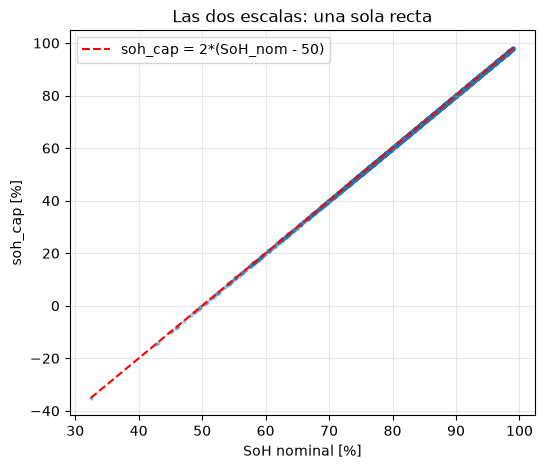

In [9]:
err = (cons["soh_cap"] - 2 * (cons["soh_nominal"] - 50)).abs()
print("desviacion maxima de la conversion: %.2e" % err.max())
print("filas con desviacion > 0,01 puntos:", (err > 0.01).sum())
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(cons["soh_nominal"], cons["soh_cap"], s=5, alpha=0.3)
xs = np.linspace(cons["soh_nominal"].min(), cons["soh_nominal"].max(), 10)
ax.plot(xs, 2 * (xs - 50), "r--", label="soh_cap = 2*(SoH_nom - 50)")
ax.set_xlabel("SoH nominal [%]")
ax.set_ylabel("soh_cap [%]")
ax.set_title("Las dos escalas: una sola recta")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

## 7. Fechas y ciclos de operación

¿En qué fechas cae el experimento y qué mide `num_cycles_op`?

In [10]:
print("primer CU:", pd.to_datetime(cons["timestamp_s"].min(), unit="s"))
print("ultimo CU:", pd.to_datetime(cons["timestamp_s"].max(), unit="s"))
print("dias entre el primer y el ultimo CU:",
      round((cons["timestamp_s"].max() - cons["timestamp_s"].min()) / 86400))
print()
print(cons.groupby("age_type")["num_cycles_op"].describe()[["count", "mean", "50%", "max"]].round(0).to_string())
print()
print("celda con mas ciclos de operacion:",
      cons.loc[cons["num_cycles_op"].idxmax(), ["cell_id", "condicion", "age_type", "cu", "num_cycles_op"]].to_dict())

primer CU: 2022-10-13 01:23:14
ultimo CU: 2024-05-31 18:02:30
dias entre el primer y el ultimo CU: 597

           count    mean     50%      max
age_type                                 
1.0       1374.0     0.0     0.0      0.0
2.0       1851.0  1260.0   856.0   8778.0
3.0        781.0  9659.0  7200.0  63884.0

celda con mas ciclos de operacion: {'cell_id': 'P076_2', 'condicion': 76, 'age_type': 3.0, 'cu': 28, 'num_cycles_op': 63884}


## Conclusiones del AED 03

| Control | Resultado |
|---|---|
| Nulos | Solo `q_chg_Ah` (1) y `q_dischg_Ah` (7): las 8 CU con una sola medida |
| Duplicados (celda, CU) | 0 |
| CU consecutivos | Sin huecos en las 228 celdas |
| Rangos | `q_Ah` 0,97–2,97 Ah; SoH nominal 32,4–99,1 %; sin valores imposibles |
| `soh_cap` negativo | 16 filas de 15 celdas: Q por debajo de 1,5 Ah, no un error |
| Monotonía | Q sube en 64 celdas, pero poco (mediana 0,017 Ah): ruido |
| Tiempo y ciclos | Monótonos en las 228 celdas, 0 violaciones |
| Consistencia de escalas | Conversión exacta (desviación máx. 3,3×10⁻⁵) |
| Condiciones | 76, con 3 celdas cada una, sin datos de edad perdidos |

**El consolidado está limpio para modelar.** Lo único a decidir al
usarlo: pasar las columnas `age_*` de `float64` a `int`/categoría, y
recordar que `num_cycles_op` no es comparable entre tipos (0 en
calendario, miles en perfil).